In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

class NetworkReplicatorSimulation:
    def __init__(self, G, num_modes, global_B, global_M, gamma=0.1, rho=0.01, neighbor_mode='auto'):
        """
        Simulator for Multi-Population Replicator Dynamics on Networks (Option A).
        """
        self.G = G
        self.num_modes = num_modes
        self.global_B = np.asarray(global_B, dtype=float)
        self.global_M = np.asarray(global_M, dtype=float)
        self.gamma = gamma
        self.rho = rho
        self.neighbor_mode = neighbor_mode
        self.states = {}
        
        # New internal attribute to store fitness history
        self.total_fitness_history = []
        
        self._initialize_network_properties()

    def _initialize_network_properties(self):
        """Initializes default node attributes (population, modal share) if not provided."""
        for node in self.G.nodes():
            if 'modal_share' in self.G.nodes[node]:
                self.states[node] = np.array(self.G.nodes[node]['modal_share'], dtype=float)
            else:
                self.states[node] = np.ones(self.num_modes) / self.num_modes
            if 'population' not in self.G.nodes[node]:
                self.G.nodes[node]['population'] = 1000.0

    def _get_spillover_neighbors(self, node):
        """Identifies neighboring nodes causing spillover."""
        if self.neighbor_mode == 'auto':
            if self.G.is_directed():
                return list(self.G.successors(node))
            else:
                return list(self.G.neighbors(node))
        elif self.neighbor_mode == 'successors' and hasattr(self.G, 'successors'):
            return list(self.G.successors(node))
        elif self.neighbor_mode == 'predecessors' and hasattr(self.G, 'predecessors'):
            return list(self.G.predecessors(node))
        else:
            return list(self.G.neighbors(node))

    def compute_costs(self):
        """Computes the current cost vector for every node."""
        costs = {}
        for node in self.G.nodes():
            B_i = np.array(self.G.nodes[node].get('B', self.global_B))
            M_i = np.array(self.G.nodes[node].get('M', self.global_M))
            x_i = self.states[node]
            local_cost = B_i + (M_i @ x_i)
            
            spillover = np.zeros(self.num_modes)
            neighbors = self._get_spillover_neighbors(node)
            for nbr in neighbors:
                weight = self.G.edges[node, nbr].get('weight', 1.0) if self.G.has_edge(node, nbr) else 1.0
                M_j = np.array(self.G.nodes[nbr].get('M', self.global_M))
                x_j = self.states[nbr]
                spillover += weight * (M_j @ x_j)
                
            costs[node] = local_cost + self.gamma * spillover
        return costs

    def step(self):
        """Executes a single synchronous step of the discrete Replicator Dynamics."""
        current_costs = self.compute_costs()
        next_states = {}
        for node in self.G.nodes():
            x = self.states[node]
            C = current_costs[node]
            mu = np.dot(x, C)
            dx = self.rho * x * (mu - C)
            new_x = x + dx
            new_x = np.clip(new_x, 1e-7, None)
            new_x /= np.sum(new_x)
            next_states[node] = new_x
        self.states = next_states

    def run_simulation(self, steps=100):
        """Runs the simulation, records state history, and calculates system fitness."""
        history = {node: [] for node in self.G.nodes()}
        self.total_fitness_history = []  # Reset fitness history at the start of a run
        
        for _ in range(steps):
            # 1. Record state history
            for node in self.G.nodes():
                history[node].append(self.states[node].copy())
            
            # 2. Compute current costs to calculate the current system-wide fitness
            current_costs = self.compute_costs()
            total_pop = 0.0
            weighted_fitness_sum = 0.0
            
            for node in self.G.nodes():
                pop = self.G.nodes[node].get('population', 1000.0)
                x = self.states[node]
                C = current_costs[node]
                
                # Mean cost (travel time) experienced by this node's population
                mu_node = np.dot(x, C)
                # Fitness is defined as the negative of the cost (payoff to maximize)
                fitness_node = -mu_node
                
                weighted_fitness_sum += pop * fitness_node
                total_pop += pop
            
            # Global population-weighted average fitness
            avg_system_fitness = weighted_fitness_sum / total_pop if total_pop > 0 else 0.0
            self.total_fitness_history.append(avg_system_fitness)
            
            # 3. Advance to the next step
            self.step()
            
        return history 

    def get_total_fitness_history(self):
        """
        Returns the recorded total system fitness over time.
        In transport dynamics, fitness is defined as the negative of the average travel time,
        weighted by the population of each node. Higher fitness means lower overall congestion.
        """
        if not self.total_fitness_history:
            raise ValueError("Simulation has not been run yet or step tracking failed. Call run_simulation() first.")
        return self.total_fitness_history    

In [6]:
# =============================================================================
# EXAMPLE USAGE & EXTENSIBILITY TEST
# =============================================================================
# Define global transport parameters (3 modes: Auto, Bus, Bike)
# B: Free-flow baseline travel times
global_B = np.array([20.0, 25.0, 35.0]) 

# M: Attrition/Congestion matrix (Direct impacts on the diagonal)
global_M = np.array([
    [45.0, 10.0,  5.0],  # Auto cost is heavily impacted by other autos
    [15.0, 20.0,  0.0],  # Bus cost impacted by autos and buses
    [ 5.0,  0.0, 15.0]   # Bike cost marginally impacted by autos
])

# Setup a small Directed Graph representing a sequential road network: Node 0 -> Node 1 -> Node 2
di_G = nx.DiGraph()
di_G.add_nodes_from([
    (0, {'population': 5000, 'modal_share': [0.7, 0.2, 0.1]}), # Mostly drivers initially
    (1, {'population': 2000}),                                 # Uniform initial split default
    (2, {'population': 8000})
])
# Add directed edges with custom weights (representing link capacities/impedance)
di_G.add_edge(0, 1, weight=1.2)
di_G.add_edge(1, 2, weight=0.8)

rho = 0.001
gamma = 1.0
total_steps = 1000
sim = NetworkReplicatorSimulation(
    di_G, num_modes=3, global_B=global_B, global_M=global_M, gamma=gamma, rho=rho
)
history = sim.run_simulation(steps=total_steps)

In [7]:
# =============================================================================
# NEW EXAMPLE USAGE: RANDOM UNDIRECTED GRAPH WITH PLOTS
# =============================================================================
# 1. Define global parameters (3 modes: Auto, Bus, Bike)
global_B = np.array([20.0, 35.0, 25.0]) 
global_M = np.array([
    [45.0, 10.0,  5.0],  # Auto cost is highly affected by other autos
    [15.0, 20.0,  0.0],  # Bus cost affected by autos and buses
    [ 5.0,  0.0, 15.0]   # Bike cost marginally affected by autos
])

# 2. Generate an Undirected Random Graph (Erdos-Renyi)
# 30 nodes (roads), edge probability of 0.15
num_nodes = 30
p_edge = 0.2
seed = 42
und_G = nx.erdos_renyi_graph(n=num_nodes, p=p_edge, seed=seed)

# 3. Initialize nodes with UNIFORM population and slightly noisy initial shares
# We add a bit of random noise so that initial states differ slightly across nodes
np.random.seed(seed)
for node in und_G.nodes():
    und_G.nodes[node]['population'] = 1000.0  # Strict uniform population setup
    
    # Start with roughly 60% Auto, 20% Bus, 20% Bike + some noise
    initial_shares = np.array([1,1,1]) / 3
    initial_shares = np.clip(initial_shares, 0.01, 1.0)
    und_G.nodes[node]['modal_share'] = initial_shares / np.sum(initial_shares)

# 4. Instantiate the simulator and run for 100 steps
# gamma=0.12 (spillover effect), rho=0.03 (adaptation speed)
rho = 0.001
gamma = 1.0
total_steps = 2000
sim = NetworkReplicatorSimulation(
    und_G, num_modes=3, global_B=global_B, global_M=global_M, gamma=gamma, rho=rho
)
history = sim.run_simulation(steps=total_steps)


In [4]:
# =============================================================================
# NEW EXAMPLE USAGE: 6x6 LATTICE GRAPH WITH GRID PLOTS
# =============================================================================
# 1. Define global parameters (3 modes: Auto, Bus, Bike)
global_B = np.array([15.0, 30.0, 20.0]) 
global_M = np.array([
    [50.0, 15.0,  5.0],  # Auto cost escalates heavily with more autos
    [20.0, 15.0,  0.0],  # Bus cost is moderately robust
    [ 5.0,  0.0, 10.0]   # Bike cost is highly insulated from congestion
])

# 2. Generate an Undirected 2D Grid Graph (6x6 Lattice)
# This creates 36 nodes, identified by tuple coordinates (i, j) where i, j in [0..5]
lattice_G = nx.grid_2d_graph(6, 6)

# 3. Setup strict UNIFORM population and uniform initial modal shares across the lattice
# Every node starts in the exact same condition to see how topology alone creates differences
seed = 123
np.random.seed(seed)

for node in lattice_G.nodes():
    lattice_G.nodes[node]['population'] = 2000.0  # Uniform population
    
    # Initial baseline: 55% Auto, 25% Bus, 20% Bike + tiny local fluctuations
    initial_shares = np.array([0.55, 0.25, 0.20]) + np.random.uniform(-0.03, 0.03, 3)
    initial_shares = np.clip(initial_shares, 0.01, 1.0)
    lattice_G.nodes[node]['modal_share'] = initial_shares / np.sum(initial_shares)

# 4. Instantiate the simulator and run for 120 steps
# gamma=0.15 (stronger spillover for compact grid layout), rho=0.025 (smooth transition)
total_steps = 120
sim = NetworkReplicatorSimulation(
    lattice_G, num_modes=3, global_B=global_B, global_M=global_M, gamma=0.15, rho=0.025
)
history = sim.run_simulation(steps=total_steps)

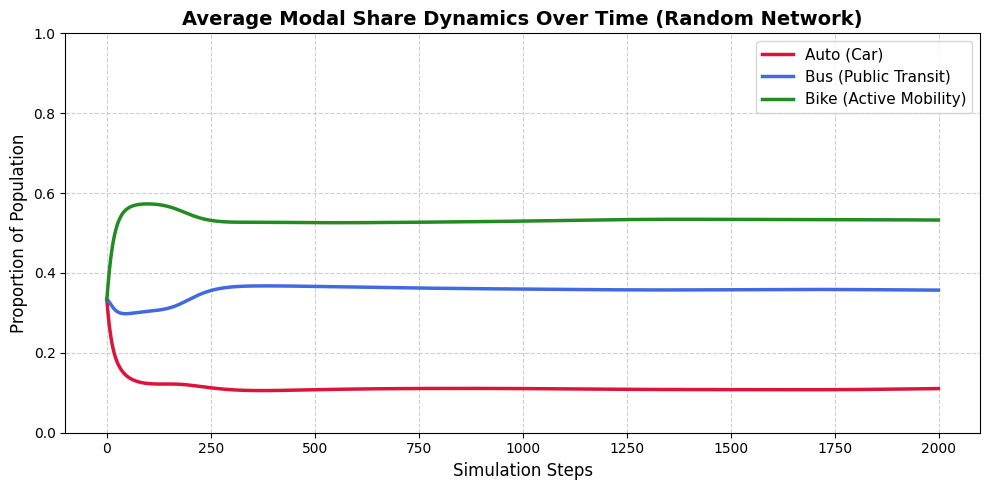

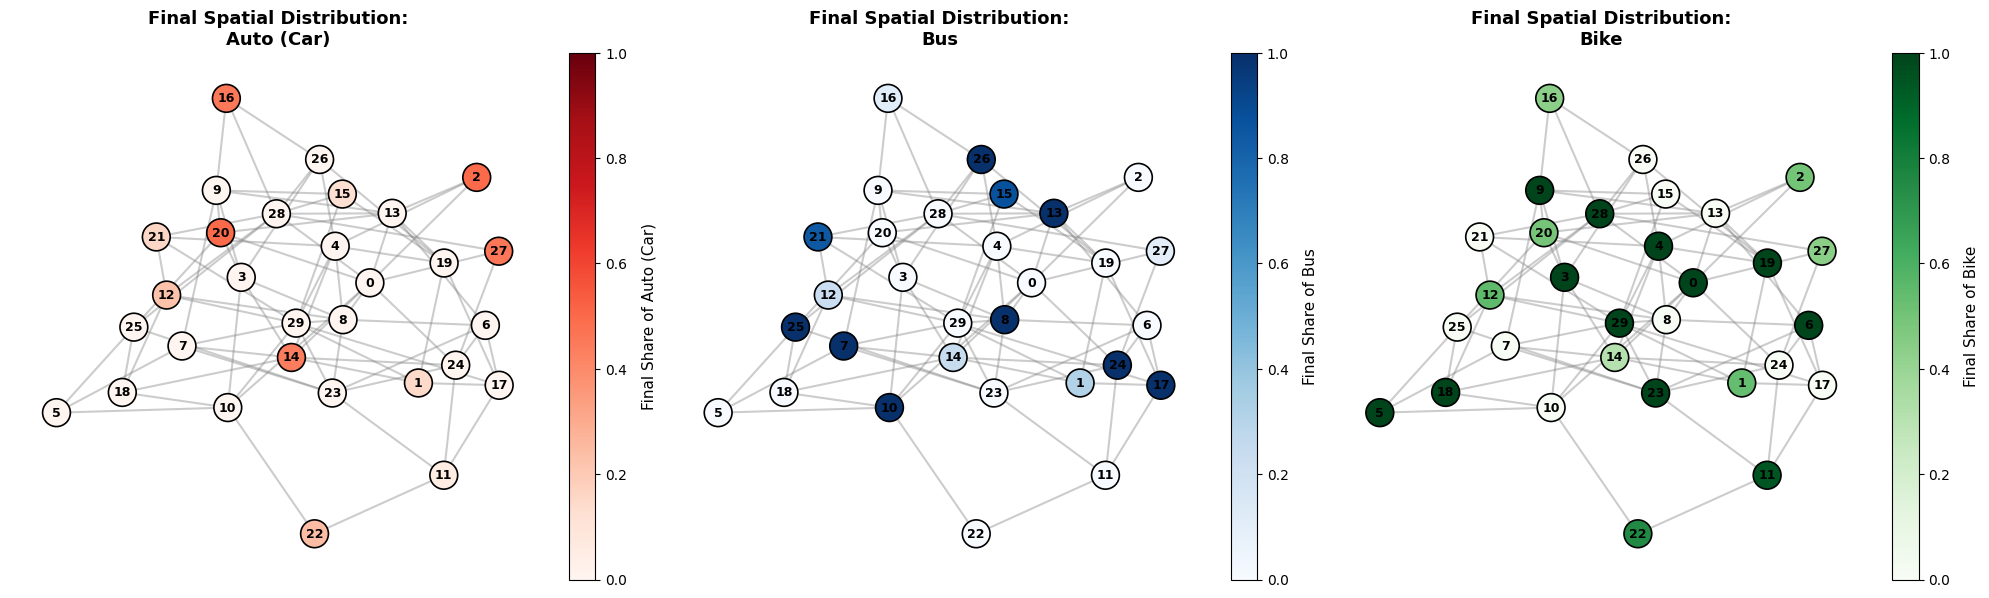

In [8]:
# =============================================================================
# PLOT 1: TIME SERIES DYNAMICS (Average across the entire network)
# =============================================================================
# Aggregate the modal shares of all nodes for each time step
graph = und_G  # Use the lattice graph for plotting

avg_history = np.zeros((total_steps, 3))
for t in range(total_steps):
    shares_at_t = [history[node][t] for node in graph.nodes()]
    avg_history[t] = np.mean(shares_at_t, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(avg_history[:, 0], label='Auto (Car)', color='crimson', linewidth=2.5)
plt.plot(avg_history[:, 1], label='Bus (Public Transit)', color='royalblue', linewidth=2.5)
plt.plot(avg_history[:, 2], label='Bike (Active Mobility)', color='forestgreen', linewidth=2.5)

plt.title('Average Modal Share Dynamics Over Time (Random Network)', fontsize=14, fontweight='bold')
plt.xlabel('Simulation Steps', fontsize=12)
plt.ylabel('Proportion of Population', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# =============================================================================
# PLOT 2: FINAL NETWORK GRAPH WITH SPATIAL DISTRIBUTION OF ALL THREE MODES
# =============================================================================
# Extract the final proportion of users for each node and mode
final_auto_shares = [sim.states[node][0] for node in graph.nodes()]
final_bus_shares = [sim.states[node][1] for node in graph.nodes()]
final_bike_shares = [sim.states[node][2] for node in graph.nodes()]

# Define a list of tuples containing metadata for each mode
modes_data = [
    ('Auto (Car)', final_auto_shares, plt.cm.Reds),
    ('Bus', final_bus_shares, plt.cm.Blues),
    ('Bike', final_bike_shares, plt.cm.Greens)
]

# Create a 1-row, 3-column subplot figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Compute spring layout ONCE so node positions are identical across all plots
pos = nx.spring_layout(graph, seed=seed)

# Loop through each axis and its corresponding mode data
for ax, (mode_name, shares, cmap) in zip(axes, modes_data):
    # Draw nodes: vmin and vmax explicitly bind the colorbar scaling from 0 to 1
    nodes = nx.draw_networkx_nodes(
        graph, pos, 
        node_color=shares, 
        cmap=cmap,         
        node_size=400, 
        edgecolors='black',
        linewidths=1.2,
        vmin=0.0,  # Minimum value for the colorbar
        vmax=1.0,  # Maximum value for the colorbar
        ax=ax
    )

    # Draw edges and labels on the specific axis
    nx.draw_networkx_edges(graph, pos, alpha=0.4, width=1.5, edge_color='gray', ax=ax)
    nx.draw_networkx_labels(graph, pos, font_size=9, font_color='black', font_weight='bold', ax=ax)

    # Add an individual colorbar for each subplot
    cbar = fig.colorbar(nodes, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(f'Final Share of {mode_name}', fontsize=11, labelpad=10)

    # Subplot customization
    ax.set_title(f'Final Spatial Distribution:\n{mode_name}', fontsize=13, fontweight='bold')
    ax.axis('off') 

plt.tight_layout()
plt.show()

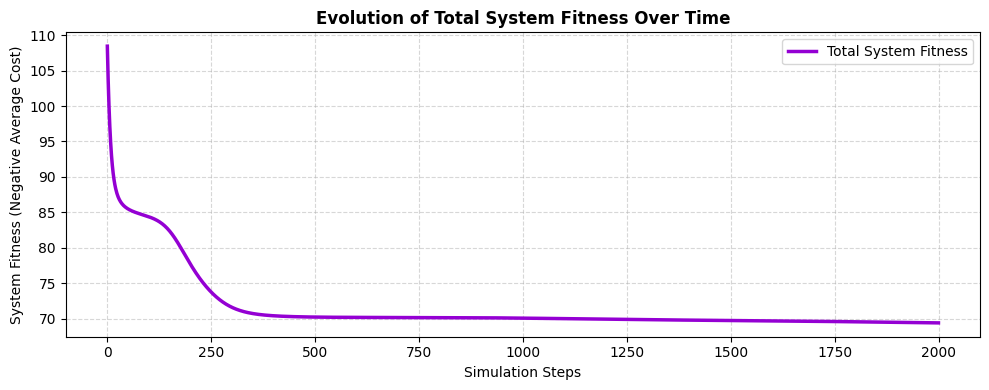

In [9]:
# --- RETRIEVE FITNESS HISTORY AT THE END ---
fitness_over_time = sim.get_total_fitness_history()

# Plotting the Fitness
plt.figure(figsize=(10, 4))
plt.plot(fitness_over_time, color='darkviolet', linewidth=2.5, label='Total System Fitness')
plt.title('Evolution of Total System Fitness Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Simulation Steps', fontsize=10)
plt.ylabel('System Fitness (Negative Average Cost)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

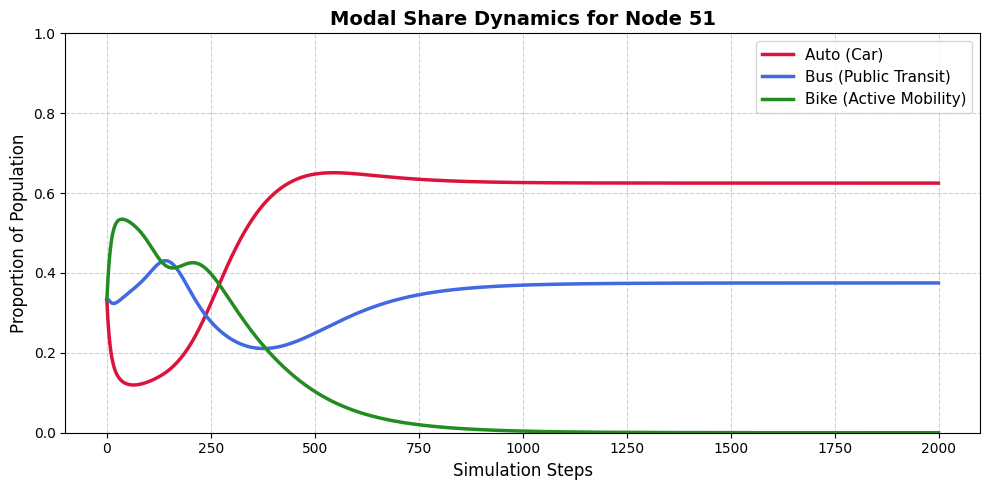

In [74]:
# one specfic node's dynamics can be visualized as follows:
node_to_visualize = np.random.randint(0, num_nodes)  # Randomly select a node to visualize
node_history = np.array(history[node_to_visualize])
plt.figure(figsize=(10, 5))   
plt.plot(node_history[:, 0], label='Auto (Car)', color='crimson', linewidth=2.5)
plt.plot(node_history[:, 1], label='Bus (Public Transit)', color='royalblue', linewidth=2.5)
plt.plot(node_history[:, 2], label='Bike (Active Mobility)', color='forestgreen', linewidth=2.5)
plt.title(f'Modal Share Dynamics for Node {node_to_visualize}', fontsize=14, fontweight='bold')
plt.xlabel('Simulation Steps', fontsize=12)
plt.ylabel('Proportion of Population', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.ylim(0, 1)
plt.show()